In [1]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pysdds

from opal import load_single_screen

# Screen at 1 mm

In [2]:
#sim_dir = "../data/opal/saved_runs/1nc_eyg5"
sim_dir = "opal_sim/tmp_run/"

In [3]:
cathode_screen = load_single_screen(os.path.join(sim_dir, "cathode_screen.h5"))
cathode_screen

{'data': {'id': array([     4,      9,     14, ..., 262112, 262143, 256543]),
  'm': array([12.16661294, 12.16661294, 12.16661294, ..., 12.16661294,
         12.16661294, 12.16661294]),
  'px': array([-0.00515486, -0.00794178, -0.00369299, ..., -0.00010776,
          0.00119276,  0.00270588]),
  'py': array([-0.00207073, -0.00635128, -0.00118475, ...,  0.00695583,
          0.01536219,  0.0112777 ]),
  'pz': array([0.42456662, 0.42126434, 0.4249613 , ..., 0.42026292, 0.42389489,
         0.43094646]),
  'q': array([-3.81469727e-15, -3.81469727e-15, -3.81469727e-15, ...,
         -3.81469727e-15, -3.81469727e-15, -3.81469727e-15]),
  'time': array([-4.38129164e-12, -4.33998090e-12, -4.38945888e-12, ...,
          4.32175026e-12,  4.25842057e-12,  3.95626043e-12]),
  'x': array([-1.22643175e-03, -1.17457564e-03, -7.59037133e-04, ...,
          1.29279235e-04,  1.53295817e-04,  7.71892377e-06]),
  'y': array([-0.00020728, -0.00134423, -0.00027142, ...,  0.0009318 ,
          0.00160166,  

In [4]:
cathode_screen['attributes']['SPOS']

array([0.001])

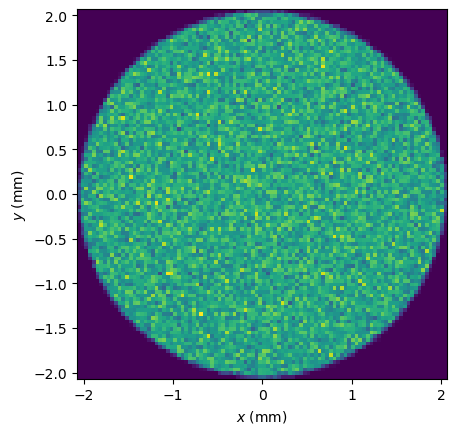

In [5]:
fig, ax = plt.subplots()
ax.hist2d(
    cathode_screen['data']['x']*1e3, 
    cathode_screen['data']['y']*1e3, 
    bins=100
)
ax.set_xlabel('$x$ (mm)')
ax.set_ylabel('$y$ (mm)')
ax.set_aspect('equal')
plt.show()

# Beam stats along beamline

In [6]:
# load beam stats
sdds = pysdds.read(os.path.join(sim_dir, 'input.sdds'))
sdds.column_names

/Users/jp/Repositories/pysdds/pysdds/readers/readers.py:2623: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_table(buf, encoding="ascii", **opts)


['t',
 's',
 'numParticles',
 'charge',
 'energy',
 'rms_x',
 'rms_y',
 'rms_s',
 'rms_px',
 'rms_py',
 'rms_ps',
 'emit_x',
 'emit_y',
 'emit_s',
 'mean_x',
 'mean_y',
 'mean_s',
 'ref_x',
 'ref_y',
 'ref_z',
 'ref_px',
 'ref_py',
 'ref_pz',
 'max_x',
 'max_y',
 'max_s',
 'xpx',
 'ypy',
 'zpz',
 'Dx',
 'DDx',
 'Dy',
 'DDy',
 'Bx_ref',
 'By_ref',
 'Bz_ref',
 'Ex_ref',
 'Ey_ref',
 'Ez_ref',
 'dE',
 'dt',
 'partsOutside',
 'DebyeLength',
 'plasmaParameter',
 'temperature',
 'rmsDensity']

In [7]:
stats = sdds.columns_to_df()
stats

,t,s,numParticles,charge,energy,rms_x,rms_y,rms_s,rms_px,rms_py,...,Ex_ref,Ey_ref,Ez_ref,dE,dt,partsOutside,DebyeLength,plasmaParameter,temperature,rmsDensity
0,-0.004186,0.000000,47,-1.792908e-13,0.000002,0.000967,0.001039,2.750785e-08,0.001337,0.001384,...,0.0,0.0,-45.551436,0.000001,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
1,-0.004011,0.000000,1056,-4.028320e-12,0.000004,0.000995,0.000991,6.374672e-08,0.001344,0.001351,...,0.0,0.0,-45.609745,0.000003,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
2,-0.003837,0.000000,5643,-2.152634e-11,0.000006,0.000995,0.000999,1.265019e-07,0.001362,0.001345,...,0.0,0.0,-45.667962,0.000006,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
3,-0.003663,0.000000,11233,-4.285049e-11,0.000013,0.001002,0.000996,2.536241e-07,0.001354,0.001344,...,0.0,0.0,-45.726086,0.000012,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
4,-0.003488,0.000000,16978,-6.476593e-11,0.000024,0.000999,0.001001,4.522470e-07,0.001351,0.001350,...,0.0,0.0,-45.784118,0.000021,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1075,72.276325,21.652424,262144,-1.000000e-09,41.794258,0.001747,0.000821,8.162578e-04,0.037867,0.006655,...,0.0,0.0,0.000000,0.079979,0.010000,0.0,0.000048,408.754008,426.727905,8.813329e+14
1076,72.376325,21.682401,262144,-1.000000e-09,41.794273,0.001754,0.000823,8.162591e-04,0.037874,0.006672,...,0.0,0.0,0.000000,0.079959,0.010000,0.0,0.000048,410.637838,426.943106,8.745869e+14
1077,72.476325,21.712378,262144,-1.000000e-09,41.794289,0.001761,0.000825,8.162603e-04,0.037881,0.006689,...,0.0,0.0,0.000000,0.079938,0.010000,0.0,0.000048,412.493129,427.157590,8.680442e+14
1078,72.576325,21.742355,262144,-1.000000e-09,41.794305,0.001768,0.000827,8.162616e-04,0.037888,0.006705,...,0.0,0.0,0.000000,0.079918,0.010000,0.0,0.000049,414.345485,427.371361,8.615925e+14


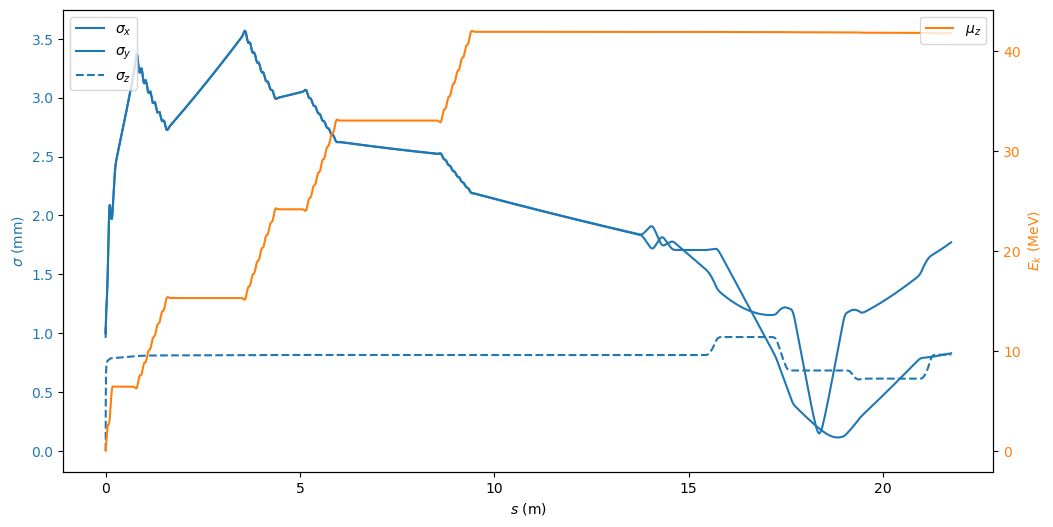

In [8]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(stats['s'], stats['rms_x']*1e3, color=colors[0], label='$\sigma _x$')
ax.plot(stats['s'], stats['rms_y']*1e3, color=colors[0], label='$\sigma _y$')
ax.plot(stats['s'], stats['rms_s']*1e3, color=colors[0], linestyle='--', label='$\sigma _z$')
ax.legend(loc='upper left')
ax.set_xlabel('$s$ (m)')
ax.set_ylabel('$\sigma$ (mm)', color=colors[0])
ax.tick_params(axis='y', labelcolor=colors[0])

ax2 = ax.twinx()
ax2.plot(stats['s'], stats['energy'], color=colors[1], label='$\mu _z$')
ax2.legend(loc='upper right')
ax2.set_ylabel('$E_k$ (MeV)', color=colors[1])
ax2.tick_params(axis='y', labelcolor=colors[1])

plt.show()

In [9]:
# include element positions for better plotting

# load design path
col_names = ['s', 'z']
design_path = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_DesignPath.dat'), 
    sep='\s+',
    skiprows=1,
    usecols=[0,3],
    names=col_names
)

# define function that transforms s to z using the design path
def z_to_s(z_value):
    idx = np.abs(design_path['z'] - z_value).argmin(axis=-1)
    return design_path['s'][idx]
z_to_s = np.vectorize(z_to_s)

# load element positions
col_names = ['label', 'z', 'x', 'y']
ele_pos = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_ElementPositions.txt'), 
    sep='\s+', 
    index_col=0, 
    names=col_names
)
# get s coordinate for each element
ele_pos['s'] = z_to_s(ele_pos['z'])
ele_pos

,z,x,y,s
label,,,,
BEGIN: CATHODE,0.000000,0.000000,0,0.000458
END: CATHODE,0.050000,0.000000,0,0.051189
ENTRY EDGE: ED2,17.146164,0.618372,0,17.244050
BEGIN: ED2,16.896164,0.527380,0,16.977254
MID: ED2,16.934756,0.541426,0,17.019222
...,...,...,...,...
END: RQ2,18.961679,0.618372,0,19.063658
BEGIN: SOL_FOCUSING,0.000000,0.000000,0,0.000458
END: SOL_FOCUSING,0.486000,0.000000,0,0.487015


In [10]:
# elements I want to plot
elements = {
    'linacs': ['GUN', 'LINAC_1', 'LINAC_2', 'LINAC_3', 'LINAC_5'],
    'quads':  ['DQ4', 'DQ5', 'DQ6', 'DQ7'],
    'dipoles': ['ED1', 'ED2', 'ED3', 'ED4'],
    'rquads':  ['RQ1', 'RQ2'],
}

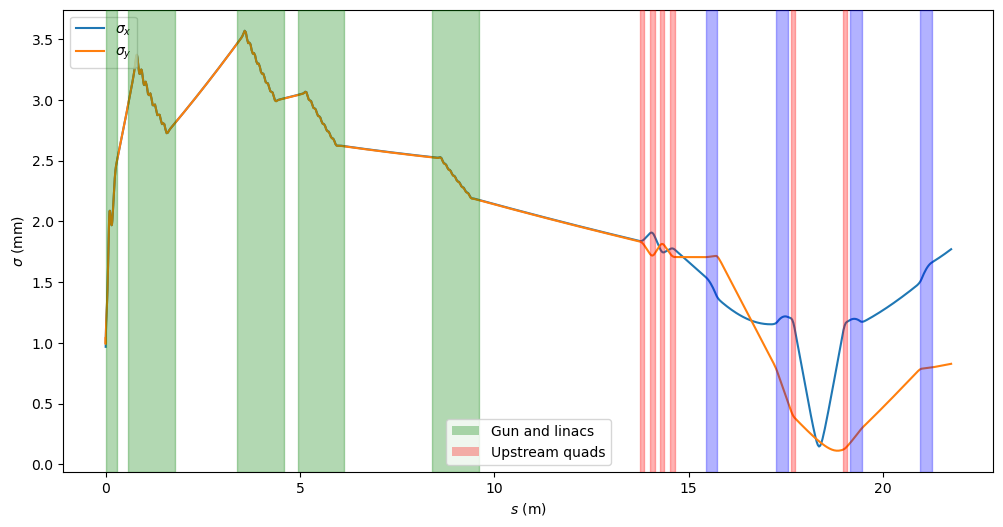

In [11]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(stats['s'], stats['rms_x']*1e3, label='$\sigma _x$')
ax.plot(stats['s'], stats['rms_y']*1e3, label='$\sigma _y$')
ax.legend(loc='upper left')
ax.set_xlabel('$s$ (m)')
ax.set_ylabel('$\sigma$ (mm)')

ax3 = ax.twinx()
for linac in elements['linacs']:
    begin = ele_pos.at[f'BEGIN: {linac}', 'z']
    end = ele_pos.at[f'END: {linac}', 'z']
    ax3.axvspan(begin, end, alpha=0.3 , color='green')
for quad in elements['quads']:
    begin = ele_pos.at[f'BEGIN: {quad}', 'z']
    end = ele_pos.at[f'END: {quad}', 'z']
    ax3.axvspan(begin, end, alpha=0.3 , color='red')
for dipole in elements['dipoles']:
    begin = ele_pos.at[f'ENTRY EDGE: {dipole}', 's']
    end = ele_pos.at[f'EXIT EDGE: {dipole}', 's']
    ax3.axvspan(begin, end, alpha=0.3 , color='blue')
for rquad in elements['rquads']:
    begin = ele_pos.at[f'BEGIN: {rquad}', 's']
    end = ele_pos.at[f'END: {rquad}', 's']
    ax3.axvspan(begin, end, alpha=0.3 , color='red')

ax3.axis('off')
legend_elements = [
    Patch(facecolor='green', alpha=0.3),
    Patch(facecolor='red', alpha=0.3),
#    Patch(facecolor='blue', alpha=0.3),
#    Patch(facecolor='red', alpha=0.3),
]
legend_labels = [
    'Gun and linacs',
    'Upstream quads',
#    'Dipoles',
#    'Reversing quads',
]
ax3.legend(legend_elements, legend_labels, loc='lower center')
plt.show()

In [12]:
stats['energy']

0        0.000002
1        0.000004
2        0.000006
3        0.000013
4        0.000024
          ...    
1075    41.794258
1076    41.794273
1077    41.794289
1078    41.794305
1079    41.794311
Name: energy, Length: 1080, dtype: float64

# Phase space at YAG4

In [13]:
yag4 = load_single_screen(os.path.join(sim_dir, 'YAG4.h5'))
yag5 = load_single_screen(os.path.join(sim_dir, 'YAG5.h5'))
eyg5 = load_single_screen(os.path.join(sim_dir, 'EYG5.h5'))

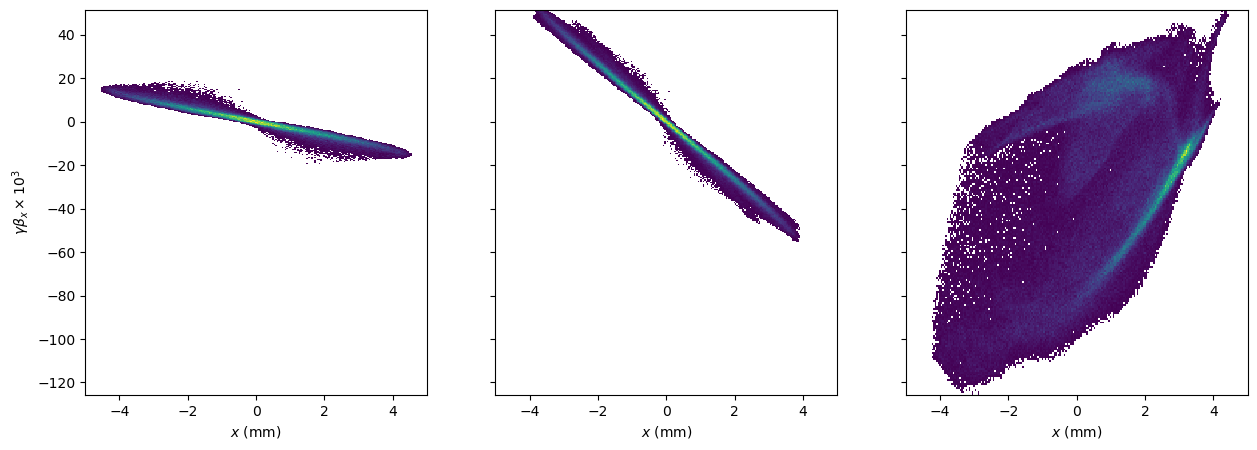

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

axs[0].hist2d(
    yag4['data']['x']*1e3, 
    yag4['data']['px']*1e3,
    bins=200,
    cmin=1
)
axs[1].hist2d(
    yag5['data']['x']*1e3, 
    yag5['data']['px']*1e3,
    bins=200,
    cmin=1
)
axs[2].hist2d(
    eyg5['data']['x']*1e3, 
    eyg5['data']['px']*1e3,
    bins=200,
    cmin=1
)

axs[0].set_ylabel('$\gamma \\beta_x \\times 10^3$')
xmin = -5
xmax = 5
for ax in axs:
    ax.set_xlabel('$x$ (mm)')
    ax.set_xlim(xmin, xmax)

plt.show()

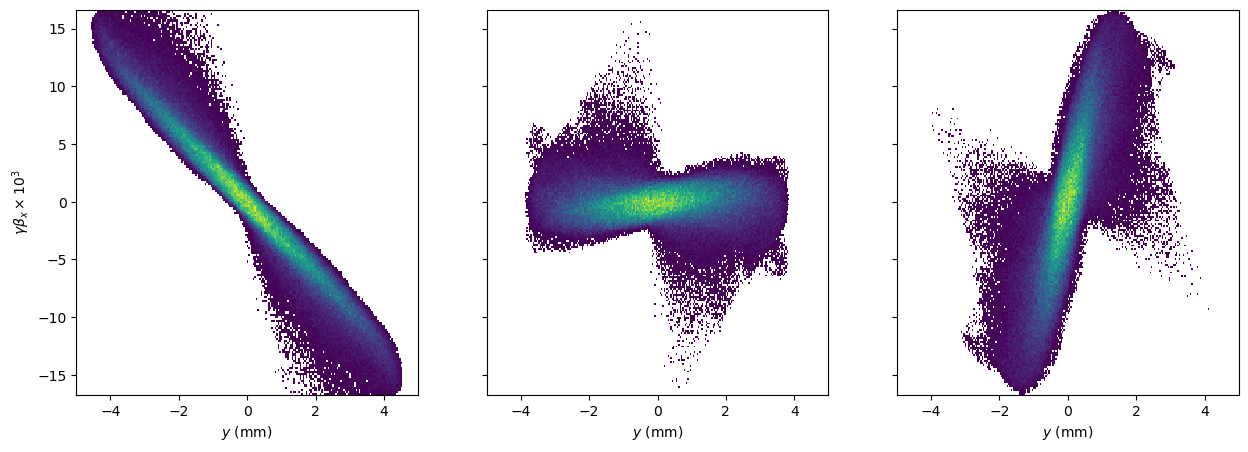

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

axs[0].hist2d(
    yag4['data']['y']*1e3, 
    yag4['data']['py']*1e3,
    bins=200,
    cmin=1
)
axs[1].hist2d(
    yag5['data']['y']*1e3, 
    yag5['data']['py']*1e3,
    bins=200,
    cmin=1
)
axs[2].hist2d(
    eyg5['data']['y']*1e3, 
    eyg5['data']['py']*1e3,
    bins=200,
    cmin=1
)

axs[0].set_ylabel('$\gamma \\beta_x \\times 10^3$')
xmin = -5
xmax = 5
for ax in axs:
    ax.set_xlabel('$y$ (mm)')
    ax.set_xlim(xmin, xmax)

plt.show()

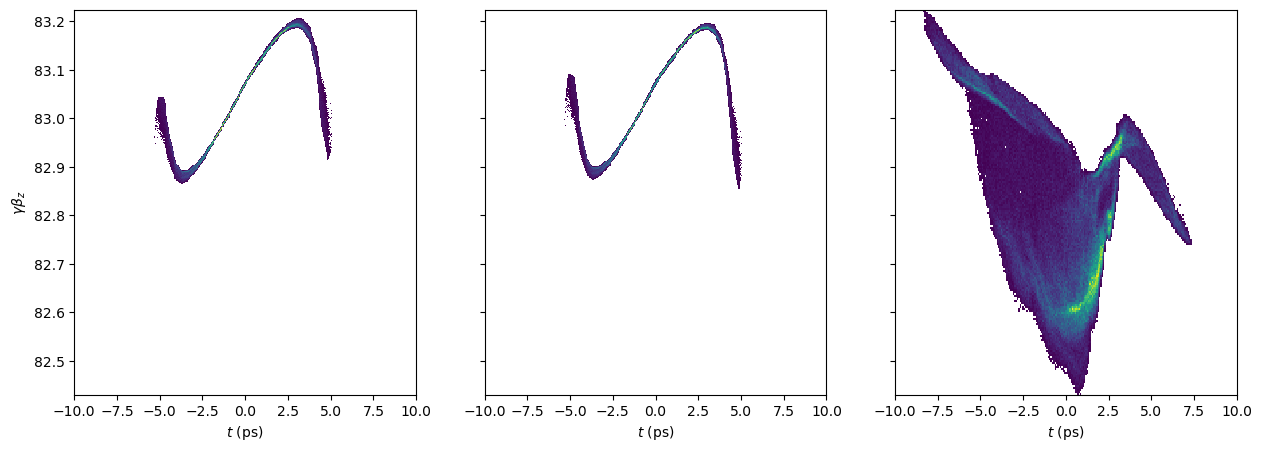

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

axs[0].hist2d(
    yag4['data']['time']*1e12, 
    yag4['data']['pz'],
    bins=200,
    cmin=1
)
axs[1].hist2d(
    yag5['data']['time']*1e12, 
    yag5['data']['pz'],
    bins=200,
    cmin=1
)
axs[2].hist2d(
    eyg5['data']['time']*1e12, 
    eyg5['data']['pz'],
    bins=200,
    cmin=1
)

axs[0].set_ylabel('$\gamma \\beta_z$')
xmin = -10
xmax = 10
for ax in axs:
    ax.set_xlabel('$t$ (ps)')
    ax.set_xlim(xmin, xmax)

plt.show()

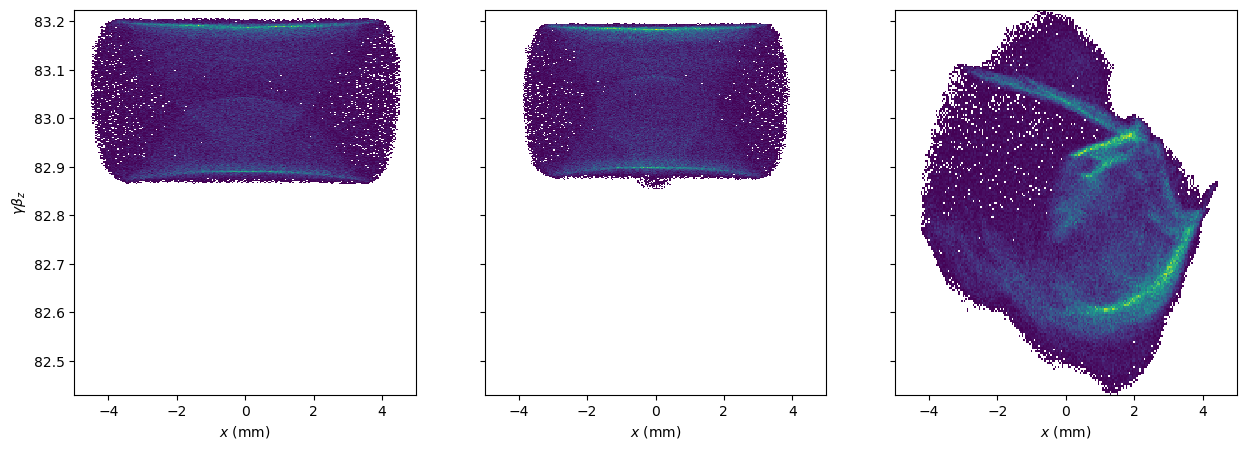

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

axs[0].hist2d(
    yag4['data']['x']*1e3, 
    yag4['data']['pz'],
    bins=200,
    cmin=1
)
axs[1].hist2d(
    yag5['data']['x']*1e3, 
    yag5['data']['pz'],
    bins=200,
    cmin=1
)
axs[2].hist2d(
    eyg5['data']['x']*1e3, 
    eyg5['data']['pz'],
    bins=200,
    cmin=1
)

axs[0].set_ylabel('$\gamma \\beta_z$')
xmin = -5
xmax = 5
for ax in axs:
    ax.set_xlabel('$x$ (mm)')
    ax.set_xlim(xmin, xmax)

plt.show()

In [17]:
yag4

{'data': {'id': array([ 38213,  35811,  63003, ...,  98993, 209791, 225191]),
  'm': array([12.16661294, 12.16661294, 12.16661294, ..., 12.16661294,
         12.16661294, 12.16661294]),
  'px': array([0.000797  , 0.00247217, 0.00184103, ..., 0.00128804, 0.0006352 ,
         0.00072874]),
  'py': array([ 0.0009728 ,  0.00888143,  0.00178165, ..., -0.00519355,
         -0.00268164,  0.00085765]),
  'pz': array([82.88977085, 82.88355123, 82.91721782, ..., 82.99486907,
         83.18592658, 83.17840666]),
  'q': array([-3.81469727e-15, -3.81469727e-15, -3.81469727e-15, ...,
         -3.81469727e-15, -3.81469727e-15, -3.81469727e-15]),
  'time': array([-3.59228230e-12, -3.39205275e-12, -2.55458004e-12, ...,
         -1.17041792e-12,  2.82738208e-12,  3.47066313e-12]),
  'x': array([-2.91081836e-04, -8.56451203e-04, -9.42061573e-04, ...,
          1.84966791e-05,  1.83900273e-05,  1.83088299e-05]),
  'y': array([-6.76732802e-05, -3.10375077e-03, -9.67821729e-04, ...,
          2.06850395e-03

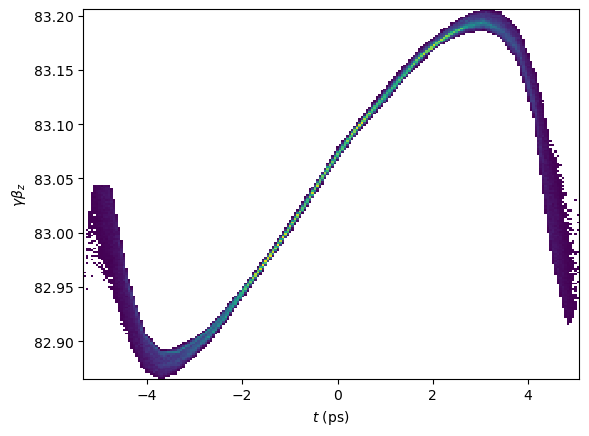

In [18]:
plt.hist2d(
    (yag4['data']['time'] - yag4['data']['time'].mean())*1e12, 
    yag4['data']['pz'],
    bins=200,
    cmin=1
)
plt.xlabel('$t$ (ps)')
plt.ylabel('$\gamma \\beta_z$')
plt.show()

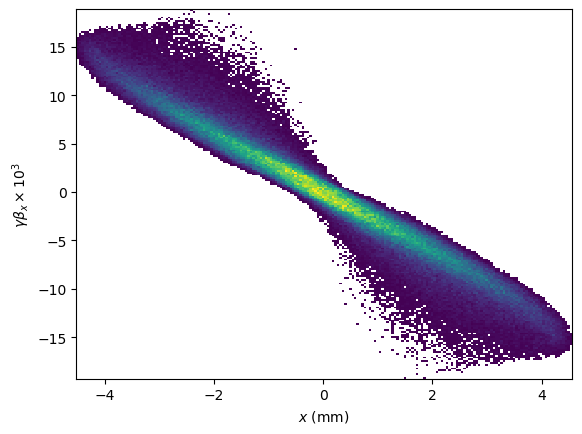

In [19]:
plt.hist2d(
    yag4['data']['x']*1e3, 
    yag4['data']['px']*1e3,
    bins=200,
    cmin=1
)
plt.xlabel('$x$ (mm)')
plt.ylabel('$\gamma \\beta_x \\times 10^3$')
plt.show()

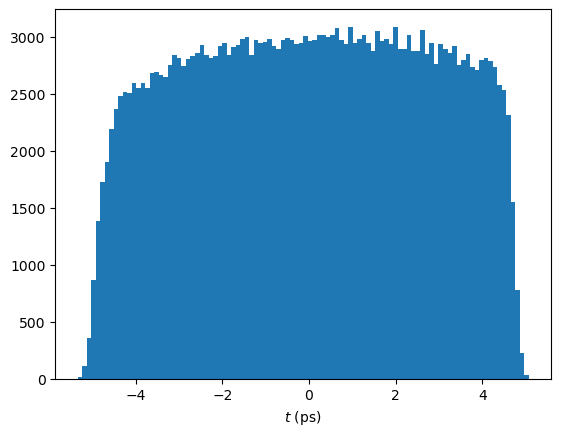

In [20]:
plt.hist(
    (yag4['data']['time']-yag4['data']['time'].mean())*1e12,
    bins=100
)
plt.xlabel('$t$ (ps)')
plt.show()